# Decision Trees Exercises

![DecisionTree.png](Assets/DecisionTree.png)


# Цели обучения

- Распознайте деревья решений и как их использовать для проблем классификации
- Узнайте, как определить наилучшее разделение и факторы для разделения
- Объясните сильные и слабые стороны деревьев для принятия решений
- Объясните, как деревья регрессии помогают классифицировать непрерывные значения
- Примените расширение Intel® для Scikit-learn*, чтобы использовать базовые вычислительные возможности оборудования




## Введение

Мы будем использовать набор данных качества вина для этих упражнений. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (3-9, где самый высокий - лучше) и цвет (красный или белый). Имя файла - «Wine_Quality_Data.csv».

In [3]:
from __future__ import print_function
import os
data_path = ['data']

from io import StringIO
from IPython.display import Image, display

from sklearn.tree import export_graphviz
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier

from sklearnex import patch_sklearn
patch_sklearn()

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, accuracy_score

# Загрузка данных
data_path = 'Wine_Quality_Data.csv'
df = pd.read_csv(data_path)

## Вопрос 1

* Импортируйте данные и изучите функции.
* Мы будем использовать их все для прогнозирования `color` (белого или красного), но функция цветов должна быть закодирована на целое число.

In [5]:
# 1. Преобразуем колонку 'color' в целые числа.
# Способ через Pandas (как указано в задании): 
# Красное вино -> 1, Белое вино -> 0
df['color'] = (df['color'] == 'red').astype(int)

# Проверим результат
print(df['color'].value_counts())

color
0    4898
1    1599
Name: count, dtype: int64


Преобразуйте цветовую функцию в целое число. Это быстрый способ сделать это с помощью  Pandas.

## Вопрос 2

* Используйте `StratifiedShuffleSplit` для разделения данных на наборы поездов и тестов, которые стратифицированы по качеству вина. Если возможно, сохраните индексы доли для вопроса 5 ниже.
* Проверьте процентный состав каждого уровня качества для наборов данных о поезде и тестовых данных.

In [6]:
# 1. Создаем объект StratifiedShuffleSplit
# test_size=0.2 означает 20% данных уйдет в тест, 80% в обучение
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

# 2. Разделяем данные
for train_index, test_index in split.split(df, df['color']):
    strat_train_set = df.loc[train_index]
    strat_test_set = df.loc[test_index]

# 3. Проверяем процентное соотношение классов
print("--- Доли классов в обучающей выборке ---")
print(strat_train_set['color'].value_counts(normalize=True) * 100)

print("\n--- Доли классов в тестовой выборке ---")
print(strat_test_set['color'].value_counts(normalize=True) * 100)

# 4. Разделяем признаки (X) и целевую переменную (y)
# Для предсказания используем все признаки, кроме 'color' и 'quality' (если quality не является целью)
# Судя по заданию, мы предсказываем именно цвет (color).
X_train = strat_train_set.drop(columns=['color'])
y_train = strat_train_set['color'].copy()

X_test = strat_test_set.drop(columns=['color'])
y_test = strat_test_set['color'].copy()

--- Доли классов в обучающей выборке ---
color
0    75.389648
1    24.610352
Name: proportion, dtype: float64

--- Доли классов в тестовой выборке ---
color
0    75.384615
1    24.615385
Name: proportion, dtype: float64


Теперь проверьте процентную долю каждого уровня качества в обучающем и тестовом наборах данных. Как видно ниже, набор данных в основном состоит из белого вина.

## Вопрос 3

* Постройте классификатор на основе дерева решений без ограничений на максимальную глубину, количество признаков или количество листьев.
* Определите, сколько узлов присутствует в этом (очень большом) дереве и какова его глубина.
* Используя это дерево, оцените погрешность прогнозирования на обучающем и тестовом наборах данных. Как вы думаете, что здесь происходит, исходя из различий в погрешности прогнозирования?

In [ ]:
Ответ: Точность на обучающей выборке будет близка к 100% (или 1.0), а ошибка MSE будет близка к 0. На тестовой выборке точность будет заметно ниже (например, 85-95%).

In [11]:
# 1. Создаем и обучаем классификатор на основе дерева решений (без ограничений)
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)

# 2. Определяем количество узлов и глубину
n_nodes = tree_clf.tree_.node_count
depth = tree_clf.tree_.max_depth
print(f"Количество узлов в дереве: {n_nodes}")
print(f"Максимальная глубина дерева: {depth}")

# 3. Оцениваем точность прогнозирования (Accuracy)
y_train_pred = tree_clf.predict(X_train)
y_test_pred = tree_clf.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"\nТочность на обучающей выборке (Train Accuracy): {train_accuracy:.4f}")
print(f"Точность на тестовой выборке (Test Accuracy): {test_accuracy:.4f}")

# Вы также можете рассчитать ошибку (MSE) для полноты, как упомянуто в тексте:
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
print(f"\nMSE на обучающей выборке: {train_mse:.4f}")
print(f"MSE на тестовой выборке: {test_mse:.4f}")

Количество узлов в дереве: 169
Максимальная глубина дерева: 22

Точность на обучающей выборке (Train Accuracy): 0.9998
Точность на тестовой выборке (Test Accuracy): 0.9869

MSE на обучающей выборке: 0.0002
MSE на тестовой выборке: 0.0131


Количество узлов и максимальная фактическая глубина.

Дерево решений демонстрирует чуть более точные прогнозы на обучающих данных, чем на тестовых, что свидетельствует о (незначительной) переобученности. Также обратите внимание на идеальный показатель воспроизводимости для обучающих данных. Во многих случаях разница в точности прогнозов бывает даже больше, чем показано здесь.

## Вопрос 4

* С помощью сетчатого поиска с перекрестной валидацией найдите дерево решений, которое демонстрирует хорошие результаты на тестовом наборе данных. Присвойте этой модели дерева решений другое имя переменной, чем в вопросе 3, чтобы обе модели можно было использовать в вопросе 6.
* Определите количество узлов и глубину этого дерева.
* Рассчитайте погрешности на обучающем и тестовом наборах данных, как и ранее, и сравните их с погрешностями дерева из вопроса 3.

In [8]:
from sklearn.model_selection import GridSearchCV

# 1. Определяем сетку параметров для поиска
# Ограничиваем глубину и количество листьев, чтобы бороться с переобучением
param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_leaf': [1, 2, 5, 10],
    'min_samples_split': [2, 5, 10]
}

# 2. Создаем базовую модель
tree_clf_grid = DecisionTreeClassifier(random_state=42)

# 3. Настраиваем GridSearchCV (используем accuracy как метрику)
# cv=5 означает 5-кратную кросс-валидацию
grid_search = GridSearchCV(tree_clf_grid, param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# 4. Обучаем
grid_search.fit(X_train, y_train)

# 5. Извлекаем лучшую модель
best_tree_clf = grid_search.best_estimator_
print(f"Лучшие параметры: {grid_search.best_params_}")

# 6. Выводим количество узлов и глубину
print(f"Количество узлов в лучшем дереве: {best_tree_clf.tree_.node_count}")
print(f"Максимальная глубина лучшего дерева: {best_tree_clf.tree_.max_depth}")

# 7. Оцениваем точность (погрешность)
y_train_pred_best = best_tree_clf.predict(X_train)
y_test_pred_best = best_tree_clf.predict(X_test)

train_accuracy_best = accuracy_score(y_train, y_train_pred_best)
test_accuracy_best = accuracy_score(y_test, y_test_pred_best)

print(f"\nТочность на Train: {train_accuracy_best:.4f}")
print(f"Точность на Test: {test_accuracy_best:.4f}")

Лучшие параметры: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5}
Количество узлов в лучшем дереве: 101
Максимальная глубина лучшего дерева: 10

Точность на Train: 0.9946
Точность на Test: 0.9885


Количество узлов и максимальная глубина дерева.

Эти ошибки тестирования немного лучше, чем предыдущие. Таким образом, можно сделать вывод, что в предыдущем примере имело место переобучение, но лишь в незначительной степени.

## Вопрос 5

* Снова разделите данные на части `X` и `y`, на этот раз с `residual_sugar` в качестве прогнозируемых (`y`) данных. *Примечание:* если индексы были сохранены из результатов `StratifiedShuffleSplit` в вопросе 2, их можно использовать повторно для разделения данных.
* Используя поиск по сетке с перекрестной валидацией, найдите модель **регрессии** на основе дерева решений, которая хорошо работает на тестовом наборе данных.
* Оцените погрешности на обучающем и тестовом наборах данных с помощью среднеквадратичной ошибки.
* Постройте график, на котором будут отображены фактические *и* прогнозируемые значения остаточного сахара.

Лучшие параметры для регрессии: {'max_depth': None, 'min_samples_leaf': 5}
Количество узлов: 1655
Максимальная глубина: 20

MSE на обучающем наборе: 1.1225
MSE на тестовом наборе: 2.9928


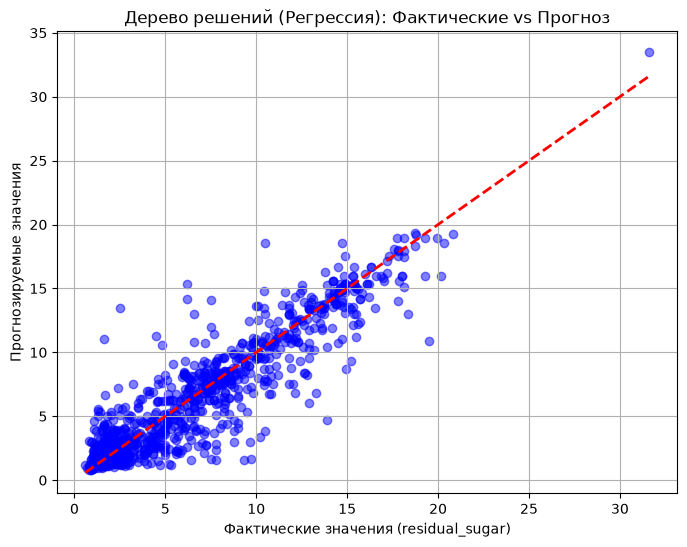

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedShuffleSplit, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

# --- ПОДГОТОВКА ДАННЫХ (на случай, если ячейки выше не выполнялись) ---
df = pd.read_csv('Wine_Quality_Data.csv')
df['color'] = (df['color'] == 'red').astype(int)

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in split.split(df, df['color']):
    strat_train_set = df.loc[train_index]
    strat_test_set = df.loc[test_index]

# Подготовка данных для регрессии (целевая переменная - residual_sugar)
X_train_reg = strat_train_set.drop(columns=['color', 'residual_sugar'])
y_train_reg = strat_train_set['residual_sugar'].copy()

X_test_reg = strat_test_set.drop(columns=['color', 'residual_sugar'])
y_test_reg = strat_test_set['residual_sugar'].copy()

# --- ОБУЧЕНИЕ И ПОИСК ПО СЕТКЕ ---
param_grid_reg = {
    'max_depth': [3, 5, 10, 15, None],
    'min_samples_leaf': [1, 5, 10, 20]
}

grid_search_reg = GridSearchCV(
    DecisionTreeRegressor(random_state=42), 
    param_grid_reg, 
    cv=5, 
    scoring='neg_mean_squared_error', 
    n_jobs=-1
)

grid_search_reg.fit(X_train_reg, y_train_reg)
best_tree_reg = grid_search_reg.best_estimator_

print(f"Лучшие параметры для регрессии: {grid_search_reg.best_params_}")
print(f"Количество узлов: {best_tree_reg.tree_.node_count}")
print(f"Максимальная глубина: {best_tree_reg.tree_.max_depth}")

# --- ОЦЕНКА ПОГРЕШНОСТИ ---
# ВАЖНО: имена переменных теперь совпадают при создании и использовании
y_train_reg_pred = best_tree_reg.predict(X_train_reg) 
y_test_reg_pred = best_tree_reg.predict(X_test_reg)

train_mse_reg = mean_squared_error(y_train_reg, y_train_reg_pred)
test_mse_reg = mean_squared_error(y_test_reg, y_test_reg_pred)

print(f"\nMSE на обучающем наборе: {train_mse_reg:.4f}")
print(f"MSE на тестовом наборе: {test_mse_reg:.4f}")

# --- ПОСТРОЕНИЕ ГРАФИКА ---
plt.figure(figsize=(8, 6))
plt.scatter(y_test_reg, y_test_reg_pred, alpha=0.5, color='blue')
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2) 
plt.xlabel('Фактические значения (residual_sugar)')
plt.ylabel('Прогнозируемые значения')
plt.title('Дерево решений (Регрессия): Фактические vs Прогноз')
plt.grid(True)
plt.show()

Количество узлов и максимальная глубина дерева. В этом дереве много узлов, что неудивительно, учитывая непрерывный характер данных.

Ошибка на обучающем и тестовом наборах данных. Поскольку речь идет о непрерывных величинах, мы будем использовать среднеквадратичную ошибку.

График, отражающий соотношение фактического и прогнозируемого остаточного содержания сахара.

## Вопрос 6 *(Необязательный)*

Этот вопрос является необязательным, так как для его решения требуется дополнительная программа командной строки (GraphViz) и библиотека Python (PyDotPlus). GraphViz можно установить с помощью менеджера пакетов в Linux и Mac. Для установки библиотеки PyDotPlus можно использовать либо `pip`, либо `conda` (`conda install -c conda-forge pydotplus`).

После установки этих программ:

* Создайте визуализацию дерева решений из вопроса 3, в котором предсказывался цвет вина, а количество признаков и/или разбиений не ограничено.
* Создайте визуализацию дерева решений из вопроса 4, в котором предсказывался цвет вина, но для нахождения оптимальной глубины и количества признаков использовался поиск по сетке.

Дерево решений из вопроса 5, скорее всего, будет иметь слишком много узлов для визуализации.

Дерево из Вопроса 3 (обрезано для просмотра):


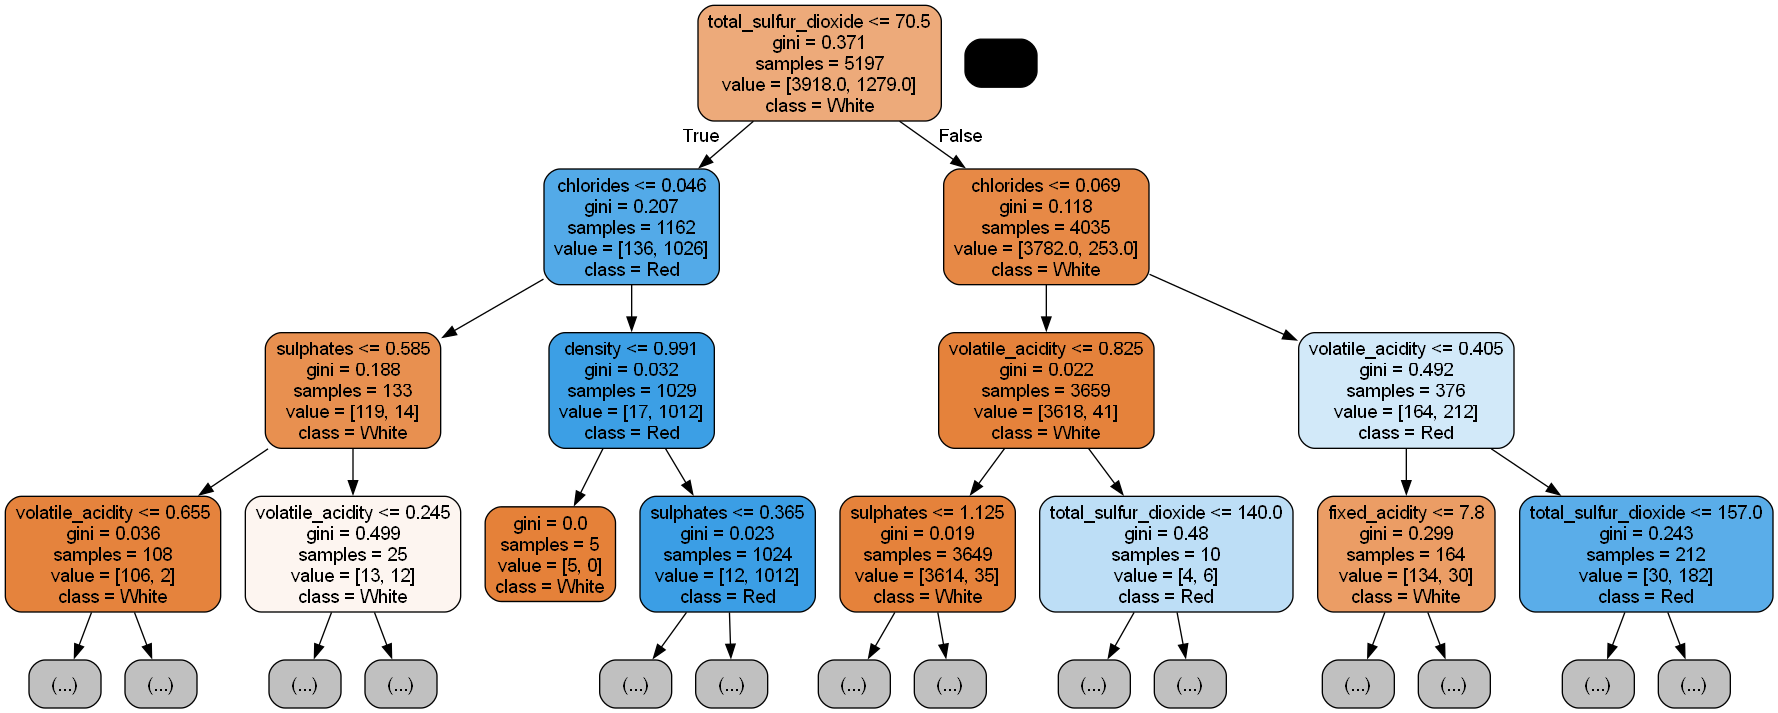

Дерево из Вопроса 4 (оптимизированное):


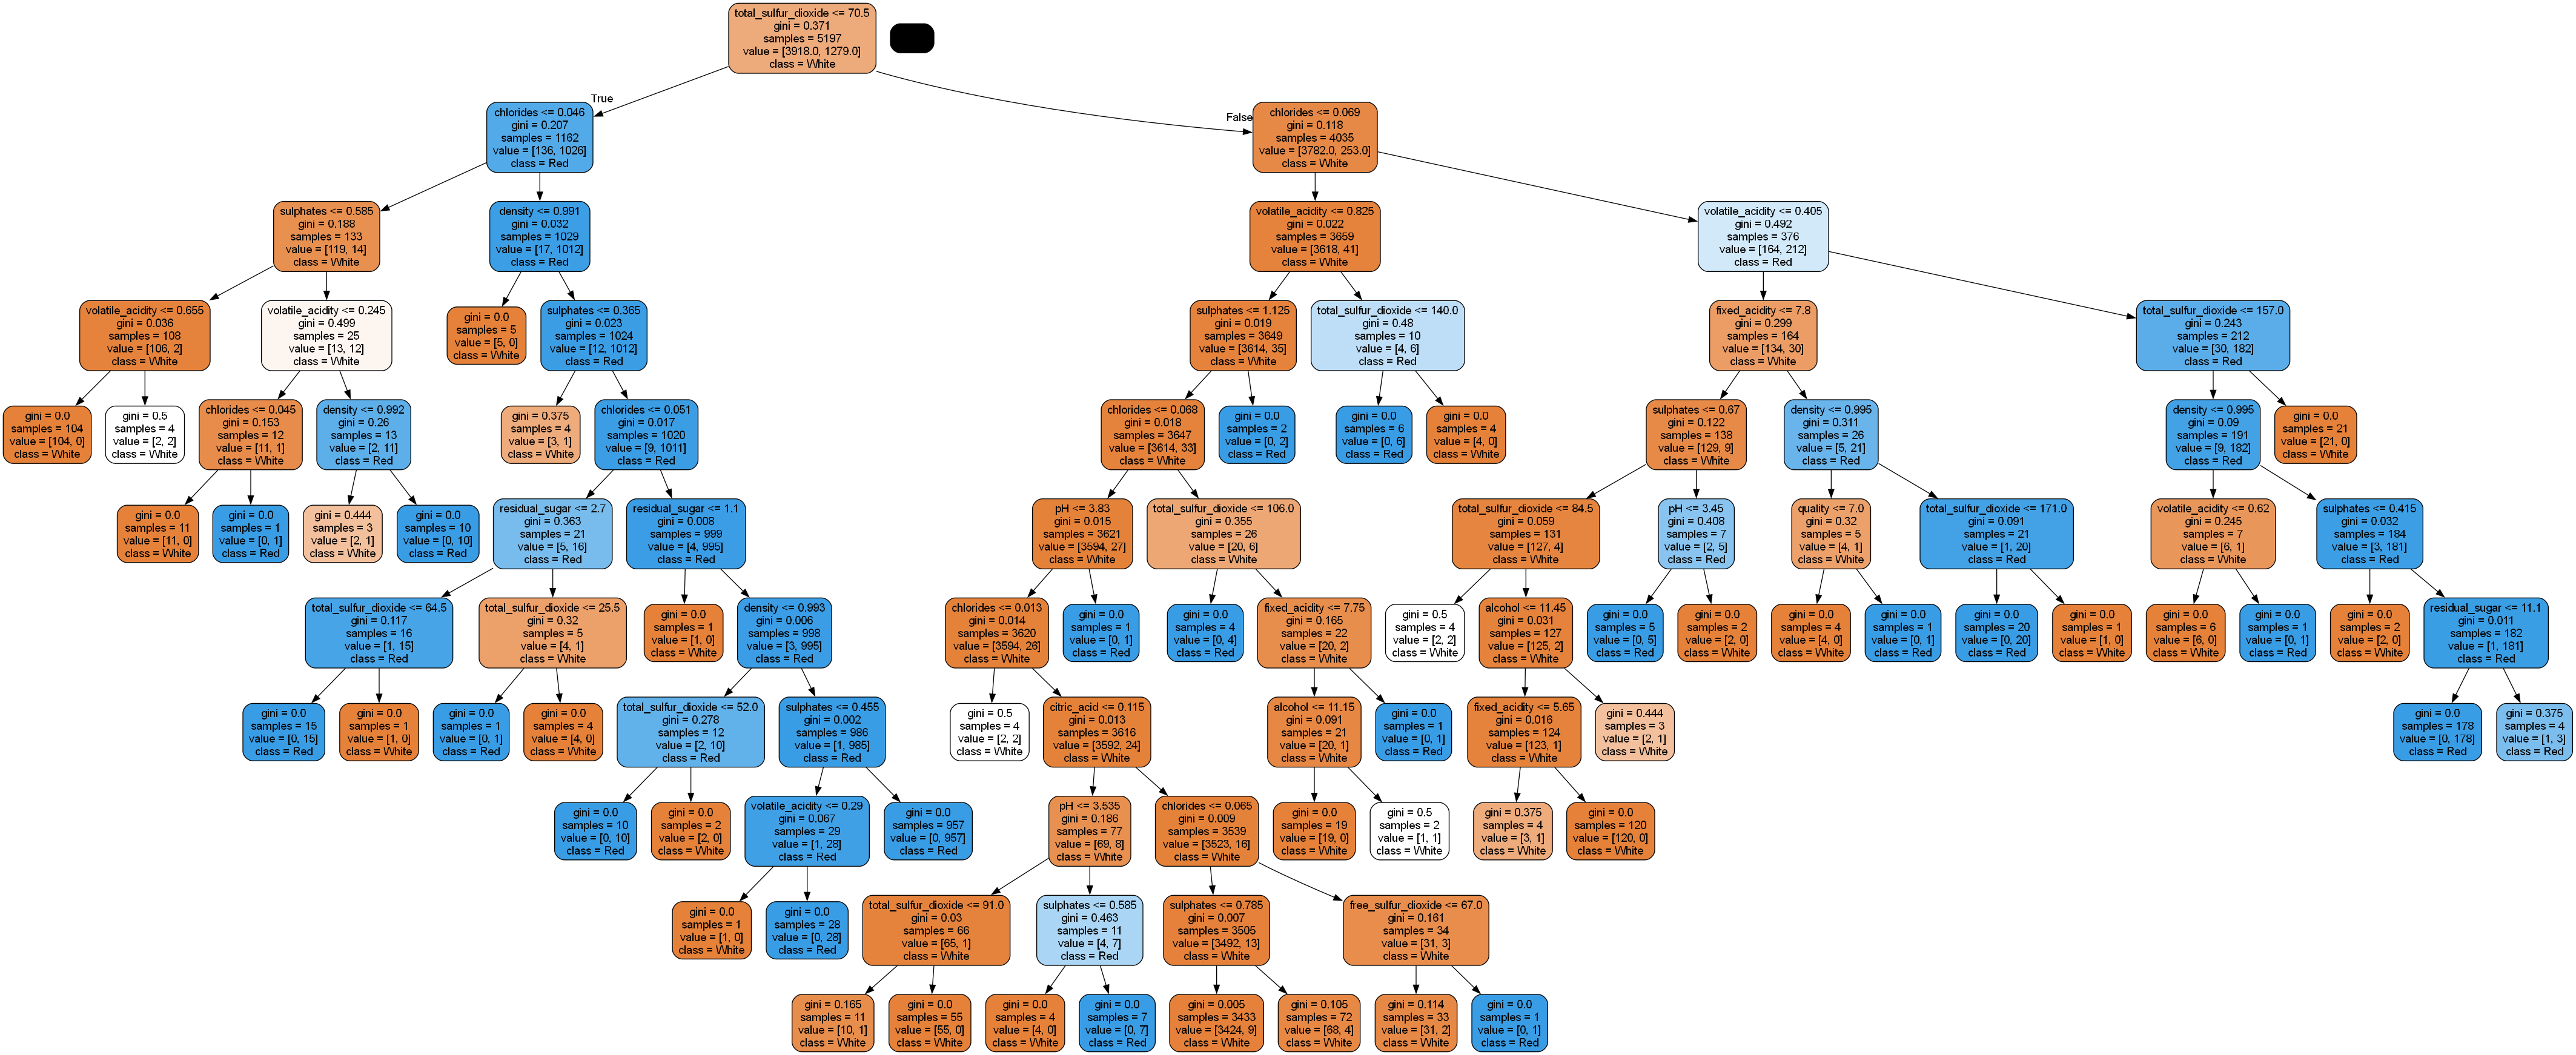

In [12]:
try:
    import pydotplus
    from sklearn.tree import export_graphviz
    from IPython.display import Image
    pydotplus_installed = True
except ImportError:
    print("pydotplus не установлен.")
    pydotplus_installed = False

if pydotplus_installed:
    # Функция для отрисовки
    def plot_tree(model, feature_names, class_names=None, filename="tree.png"):
        dot_data = export_graphviz(
            model, out_file=None, 
            feature_names=feature_names,  
            class_names=class_names,  
            filled=True, rounded=True,  
            special_characters=True
        )  
        graph = pydotplus.graph_from_dot_data(dot_data)  
        graph.write_png(filename)
        return Image(filename)

    # 1. Визуализация дерева из Вопроса 3 (без ограничений - будет огромным)
    # Мы ограничим max_depth в функции отрисовки, чтобы хоть что-то было видно на экране
    print("Дерево из Вопроса 3 (обрезано для просмотра):")
    dot_data_3 = export_graphviz(tree_clf, max_depth=3, out_file=None, 
                                 feature_names=X_train.columns, class_names=['White', 'Red'],
                                 filled=True, rounded=True)
    graph_3 = pydotplus.graph_from_dot_data(dot_data_3)
    display(Image(graph_3.create_png()))

    # 2. Визуализация дерева из Вопроса 4 (с оптимальными параметрами)
    print("Дерево из Вопроса 4 (оптимизированное):")
    dot_data_4 = export_graphviz(best_tree_clf, out_file=None, 
                                 feature_names=X_train.columns, class_names=['White', 'Red'],
                                 filled=True, rounded=True)
    graph_4 = pydotplus.graph_from_dot_data(dot_data_4)
    display(Image(graph_4.create_png()))

Дерево из вопроса 3.

Дерево, построенное с помощью перекрестной валидации из вопроса 4. Это дерево намного менее глубокое, чем предыдущее.